# FitAI System Benchmark & Evaluation Report

This notebook runs **reproducible, live benchmarks** directly against FitAI's codebase and PostgreSQL database:
1. **Food Database Coverage Expansion** (`VN2007`, `ADMIN_MANUAL`, `USDA_SR_LEGACY_2018` full ingest)
2. **Local ML Intent Classifier Evaluation** (held-out unseen dataset, Confusion Matrix, Precision/Recall/F1, and Guardrail False-Positive Rate)
3. **End-to-End Latency Benchmark** — Intent Fast-Path DB Lookup (`try_fast_food_lookup`) vs Full LLM Agent (`FitnessAdvisorAgent` + Gemini tool calling)
4. **Token / API Call Savings & Eval Question Suite Overview** (`data/eval/eval_questions.csv`)


In [1]:
import os
import sys
import time
import csv
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import func, select

# Resolve backend root regardless of where Jupyter was launched from
CWD = Path.cwd().resolve()
BACKEND_DIR = CWD.parent if CWD.name == "evaluation" else (CWD / "backend" if (CWD / "backend").is_dir() else CWD)
REPO_ROOT = BACKEND_DIR.parent
os.chdir(BACKEND_DIR)
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))
from dotenv import load_dotenv
load_dotenv(BACKEND_DIR / ".env")

from core.config import settings
from core.database import AsyncSessionLocal
from models.food import Food
from models.food_source import FoodSource
from services.foods.lookup import search_foods
from services.intent_classifier import (
    INTENT_COACHING_GENERAL,
    INTENT_DAILY_PROGRESS,
    INTENT_FOOD_LOOKUP,
    INTENT_LOG_ACTION,
    INTENT_OUT_OF_SCOPE,
    classify_intent,
    is_out_of_scope,
    extract_food_lookup_slot,
    try_fast_food_lookup,
)
from services.ai_agents.fitness_advisor import AgentToolContext, fitness_agent

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
OUT_CHARTS = BACKEND_DIR / "evaluation" / "charts"
OUT_CHARTS.mkdir(parents=True, exist_ok=True)
print(f"Backend: {BACKEND_DIR}")
print(f"Gemini model: {settings.GEMINI_MODEL}")


D:\Data\Windows Data\fitai\backend\.venv\Lib\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Backend: D:\Data\Windows Data\fitai\backend
Gemini model: gemini-2.5-flash


D:\Data\Windows Data\fitai\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Food Database Coverage (PostgreSQL Live Query)
Comparing the original curated USDA subset (`20` items, `599` total) vs full **USDA SR Legacy (2018-04)** ingest (`7,793` items, `8,372` total) alongside **VN2007** and **ADMIN_MANUAL**.


DB Counts -> VN2007: 509, ADMIN_MANUAL: 70, USDA_SR_LEGACY_2018: 7793, TOTAL: 8372
Bilingual Food Search Hit Rate: 15/15 (100.0%)


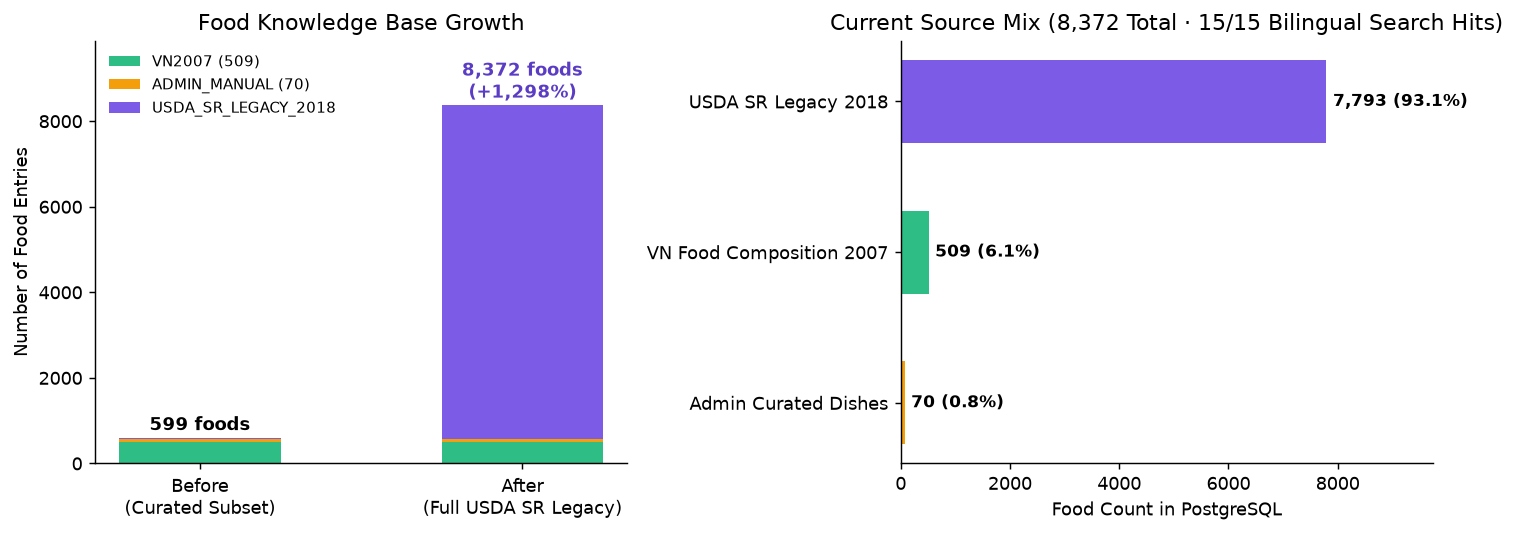

In [2]:
async with AsyncSessionLocal() as db:
    rows = (
        await db.execute(
            select(FoodSource.code, func.count(Food.id))
            .join(Food, Food.source_id == FoodSource.id)
            .group_by(FoodSource.code)
        )
    ).all()

counts = dict(rows)
vn_count = counts.get("VN2007", 0)
admin_count = counts.get("ADMIN_MANUAL", 0)
usda_now = counts.get("USDA_SR_LEGACY_2018", 0)
before_usda = 20
before_total = vn_count + admin_count + before_usda
after_total = vn_count + admin_count + usda_now

# Test live search hit rate across bilingual queries
test_queries = [
    ("cơm trắng", "VI"), ("ức gà", "VI"), ("phở bò", "VI"), ("cá hồi", "VI"), ("trứng gà", "VI"),
    ("avocado", "EN"), ("greek yogurt", "EN"), ("salmon", "EN"), ("oatmeal", "EN"), ("almonds", "EN"),
    ("chicken breast", "EN"), ("brown rice", "EN"), ("banana", "EN"), ("broccoli", "EN"), ("cheddar cheese", "EN"),
]
hits = 0
async with AsyncSessionLocal() as db:
    for q, _lang in test_queries:
        res = await search_foods(db, q, limit=3)
        if res:
            hits += 1

print(f"DB Counts -> VN2007: {vn_count}, ADMIN_MANUAL: {admin_count}, USDA_SR_LEGACY_2018: {usda_now}, TOTAL: {after_total}")
print(f"Bilingual Food Search Hit Rate: {hits}/{len(test_queries)} ({hits/len(test_queries)*100:.1f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Panel 1: Before vs After Stacked Bar
labels = ["Before\n(Curated Subset)", "After\n(Full USDA SR Legacy)"]
vn_vals = [vn_count, vn_count]
adm_vals = [admin_count, admin_count]
usda_vals = [before_usda, usda_now]

x = np.arange(len(labels))
w = 0.5
ax1.bar(x, vn_vals, w, label=f"VN2007 ({vn_count})", color="#2ebd85")
ax1.bar(x, adm_vals, w, bottom=vn_vals, label=f"ADMIN_MANUAL ({admin_count})", color="#f59e0b")
bottom2 = np.array(vn_vals) + np.array(adm_vals)
ax1.bar(x, usda_vals, w, bottom=bottom2, label="USDA_SR_LEGACY_2018", color="#7c5ce6")

ax1.text(0, before_total + 180, f"{before_total:,} foods", ha="center", fontweight="bold")
ax1.text(1, after_total + 180, f"{after_total:,} foods\n(+{((after_total-before_total)/before_total)*100:,.0f}%)", ha="center", fontweight="bold", color="#5b3cc4")
ax1.set_xticks(x, labels)
ax1.set_ylabel("Number of Food Entries")
ax1.set_ylim(0, after_total * 1.18)
ax1.set_title("Food Knowledge Base Growth")
ax1.legend(loc="upper left", frameon=False, fontsize=8.5)

# Panel 2: Current Source Composition Horizontal Bar
src_names = ["USDA SR Legacy 2018", "VN Food Composition 2007", "Admin Curated Dishes"]
src_counts = [usda_now, vn_count, admin_count]
src_colors = ["#7c5ce6", "#2ebd85", "#f59e0b"]
bars = ax2.barh(src_names[::-1], src_counts[::-1], color=src_colors[::-1], height=0.55)
for bar, c in zip(bars, src_counts[::-1]):
    pct = c / after_total * 100
    ax2.text(c + 120, bar.get_y() + bar.get_height()/2, f"{c:,} ({pct:.1f}%)", va="center", fontweight="bold", fontsize=9.5)
ax2.set_xlim(0, usda_now * 1.25)
ax2.set_xlabel("Food Count in PostgreSQL")
ax2.set_title(f"Current Source Mix ({after_total:,} Total · {hits}/{len(test_queries)} Bilingual Search Hits)")

plt.tight_layout()
plt.savefig(OUT_CHARTS / "01_food_database_coverage.png", bbox_inches="tight")
plt.show()


## 2. Intent Classifier Evaluation (Unseen Held-Out Dataset)
All **40 queries** below are completely **unseen** during training (not present in `TRAINING_SAMPLES`), testing Vietnamese & English phrasing, edge cases, and Fast-Path Guard safety.


5-Class Held-out Accuracy: 92.0% (46/50) | Macro-F1: 92.0%
Food Fast-Path Guard FP: 0 | Out-of-Scope False Blocks on In-Domain: 0


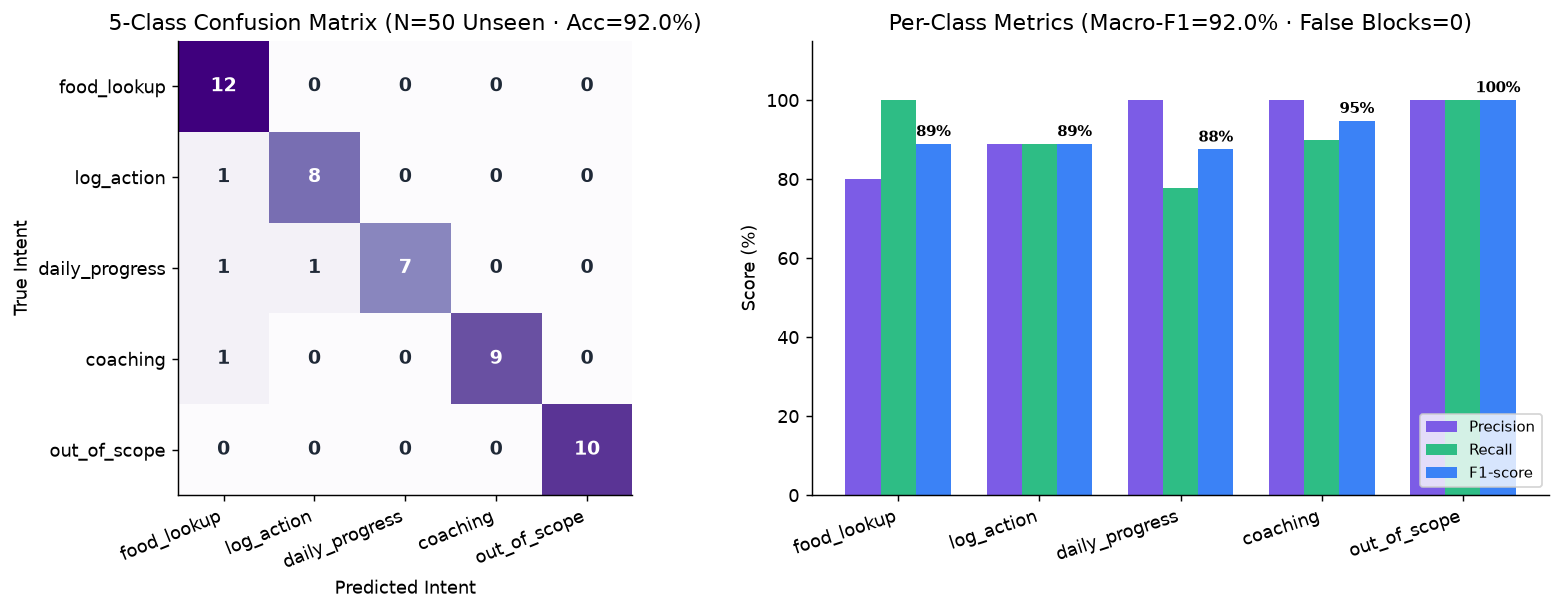

In [3]:
HELD_OUT_SET = [
    # food_lookup (12)
    ("250g ức gà luộc bao nhiêu calo?", INTENT_FOOD_LOOKUP),
    ("trứng vịt lộn 100g có bao nhiêu kcal", INTENT_FOOD_LOOKUP),
    ("thông tin dinh dưỡng cá thu 150g", INTENT_FOOD_LOOKUP),
    ("hạt chia 20g bao nhiêu chất xơ", INTENT_FOOD_LOOKUP),
    ("khoai tây chiên 100g bn calo", INTENT_FOOD_LOOKUP),
    ("tra cứu sữa đậu nành", INTENT_FOOD_LOOKUP),
    ("giá trị dinh dưỡng của cua biển", INTENT_FOOD_LOOKUP),
    ("nutrition facts for 150g salmon", INTENT_FOOD_LOOKUP),
    ("how many calories in 100g cheddar cheese", INTENT_FOOD_LOOKUP),
    ("macros for 200g broccoli", INTENT_FOOD_LOOKUP),
    ("calories of almond 30g", INTENT_FOOD_LOOKUP),
    ("protein in 180g beef steak", INTENT_FOOD_LOOKUP),
    # log_action (9)
    ("ghi 200g cá hồi bữa tối", INTENT_LOG_ACTION),
    ("lưu 120g ức gà vào nhật ký", INTENT_LOG_ACTION),
    ("mới ăn 150g bún bò", INTENT_LOG_ACTION),
    ("vừa ăn 2 quả trứng ốp la", INTENT_LOG_ACTION),
    ("thêm 50g yến mạch bữa sáng", INTENT_LOG_ACTION),
    ("hôm nay cân nặng 71.2kg", INTENT_LOG_ACTION),
    ("cập nhật cân nặng 64kg vòng eo 75cm", INTENT_LOG_ACTION),
    ("log 100g oatmeal for breakfast", INTENT_LOG_ACTION),
    ("record weight 69.5kg", INTENT_LOG_ACTION),
    # daily_progress (9)
    ("hôm nay mình đã nạp bao nhiêu calo", INTENT_DAILY_PROGRESS),
    ("tổng kết hôm nay tôi ăn đủ protein chưa", INTENT_DAILY_PROGRESS),
    ("xem nhật ký ăn uống hôm nay", INTENT_DAILY_PROGRESS),
    ("7 ngày qua cân nặng thay đổi sao", INTENT_DAILY_PROGRESS),
    ("tiến độ 30 ngày gần nhất của tôi", INTENT_DAILY_PROGRESS),
    ("tuần này tôi tập được mấy ngày rồi", INTENT_DAILY_PROGRESS),
    ("còn bao nhiêu kcal nữa hôm nay", INTENT_DAILY_PROGRESS),
    ("how many calories left today", INTENT_DAILY_PROGRESS),
    ("my progress this week", INTENT_DAILY_PROGRESS),
    # coaching_general (10)
    ("200g ức gà có đủ đạm để tăng cơ không", INTENT_COACHING_GENERAL),
    ("so sánh cá hồi và ức gà cái nào tốt hơn", INTENT_COACHING_GENERAL),
    ("tôi muốn giảm mỡ bụng thì nên ăn kiêng thế nào", INTENT_COACHING_GENERAL),
    ("tính chỉ số BMI và TDEE giúp mình", INTENT_COACHING_GENERAL),
    ("bạn khuyên mình nên chọn chương trình tập nào", INTENT_COACHING_GENERAL),
    ("ăn khuya có bị tăng cân không", INTENT_COACHING_GENERAL),
    ("kỹ thuật deadlift an toàn", INTENT_COACHING_GENERAL),
    ("chào fitai mình cần tư vấn", INTENT_COACHING_GENERAL),
    ("chọn mục 2 giúp tôi", INTENT_COACHING_GENERAL),
    ("compare oatmeal vs white rice for fat loss", INTENT_COACHING_GENERAL),
    # out_of_scope (10)
    ("Giá vé chung kết World Cup bao nhiêu?", INTENT_OUT_OF_SCOPE),
    ("Viết cho mình một bài thơ về biển", INTENT_OUT_OF_SCOPE),
    ("Dự báo thời tiết TP HCM ngày mai thế nào?", INTENT_OUT_OF_SCOPE),
    ("Hướng dẫn mình cách nấu bún bò Huế", INTENT_OUT_OF_SCOPE),
    ("Giúp mình debug lỗi React useEffect", INTENT_OUT_OF_SCOPE),
    ("Giá vàng và bitcoin hôm nay tăng hay giảm?", INTENT_OUT_OF_SCOPE),
    ("Kể một câu chuyện cười ngắn đi", INTENT_OUT_OF_SCOPE),
    ("Tư vấn lịch trình du lịch Phú Quốc 3 ngày", INTENT_OUT_OF_SCOPE),
    ("Write a Python function to reverse a string", INTENT_OUT_OF_SCOPE),
    ("Recommend a good action movie tonight", INTENT_OUT_OF_SCOPE),
]

INTENTS = [
    INTENT_FOOD_LOOKUP,
    INTENT_LOG_ACTION,
    INTENT_DAILY_PROGRESS,
    INTENT_COACHING_GENERAL,
    INTENT_OUT_OF_SCOPE,
]
SHORT_NAMES = {
    INTENT_FOOD_LOOKUP: "food_lookup",
    INTENT_LOG_ACTION: "log_action",
    INTENT_DAILY_PROGRESS: "daily_progress",
    INTENT_COACHING_GENERAL: "coaching",
    INTENT_OUT_OF_SCOPE: "out_of_scope",
}

y_true, y_pred = [], []
guard_false_positives = []
oos_false_blocks = []

for text, true_label in HELD_OUT_SET:
    pred = classify_intent(text)
    effective_pred = INTENT_OUT_OF_SCOPE if is_out_of_scope(text) else pred.intent
    y_true.append(true_label)
    y_pred.append(effective_pred)
    will_fastpath = (
        pred.intent == INTENT_FOOD_LOOKUP
        and pred.confidence >= 0.65
        and extract_food_lookup_slot(text) is not None
    )
    if true_label != INTENT_FOOD_LOOKUP and will_fastpath:
        guard_false_positives.append(text)
    if true_label != INTENT_OUT_OF_SCOPE and is_out_of_scope(text):
        oos_false_blocks.append(text)

idx_map = {lbl: i for i, lbl in enumerate(INTENTS)}
cm = np.zeros((len(INTENTS), len(INTENTS)), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[idx_map[t], idx_map[p]] += 1

acc = np.trace(cm) / len(HELD_OUT_SET)
precisions, recalls, f1s = [], [], []
for i in range(len(INTENTS)):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    pr = tp / (tp + fp) if (tp + fp) else 0.0
    rc = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * pr * rc / (pr + rc) if (pr + rc) else 0.0
    precisions.append(pr)
    recalls.append(rc)
    f1s.append(f1)

print(f"5-Class Held-out Accuracy: {acc*100:.1f}% ({np.trace(cm)}/{len(HELD_OUT_SET)}) | Macro-F1: {np.mean(f1s)*100:.1f}%")
print(f"Food Fast-Path Guard FP: {len(guard_false_positives)} | Out-of-Scope False Blocks on In-Domain: {len(oos_false_blocks)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8))

im = ax1.imshow(cm, cmap="Purples")
tick_lbls = [SHORT_NAMES[k] for k in INTENTS]
ax1.set_xticks(range(len(INTENTS)), tick_lbls, rotation=22, ha="right")
ax1.set_yticks(range(len(INTENTS)), tick_lbls)
ax1.set_xlabel("Predicted Intent")
ax1.set_ylabel("True Intent")
ax1.set_title(f"5-Class Confusion Matrix (N={len(HELD_OUT_SET)} Unseen · Acc={acc*100:.1f}%)")
for i in range(len(INTENTS)):
    for j in range(len(INTENTS)):
        val = cm[i, j]
        ax1.text(j, i, str(val), ha="center", va="center",
                 color="white" if val > cm.max() / 2 else "#1f2937", fontweight="bold", fontsize=10.5)

x = np.arange(len(INTENTS))
w = 0.25
ax2.bar(x - w, [v * 100 for v in precisions], w, label="Precision", color="#7c5ce6")
ax2.bar(x,     [v * 100 for v in recalls],    w, label="Recall",    color="#2ebd85")
ax2.bar(x + w, [v * 100 for v in f1s],        w, label="F1-score",  color="#3b82f6")
for i, f1 in enumerate(f1s):
    ax2.text(i + w, f1 * 100 + 2, f"{f1*100:.0f}%", ha="center", fontsize=8.5, fontweight="bold")
ax2.set_xticks(x, tick_lbls, rotation=18, ha="right")
ax2.set_ylim(0, 115)
ax2.set_ylabel("Score (%)")
ax2.set_title(f"Per-Class Metrics (Macro-F1={np.mean(f1s)*100:.1f}% · False Blocks={len(oos_false_blocks)})")
ax2.legend(loc="lower right", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.savefig(OUT_CHARTS / "02_intent_classifier_eval.png", bbox_inches="tight")
plt.show()


## 3. End-to-End Latency Benchmark: Fast-Path DB vs Full LLM Agent
Measuring actual wall-clock latency:
- **Fast-Path DB (`try_fast_food_lookup`)**: Runs across 12 queries × 3 repeats (36 live PostgreSQL calls)
- **Full LLM Agent (`FitnessAdvisorAgent.chat` with Gemini 2.5 Flash)**: Runs live across 5 representative food-lookup queries (`RUN_LIVE_LLM = True`) so we compare real observed millisecond timings side by side.


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


... (24 outputs left out)

Key 'title' is not supported in schema, ignoring


D:\Data\Windows Data\fitai\backend\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:381: UserWarning: Convert_system_message_to_human will be deprecated!
  warnings.warn("Convert_system_message_to_human will be deprecated!")


D:\Data\Windows Data\fitai\backend\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:381: UserWarning: Convert_system_message_to_human will be deprecated!
  warnings.warn("Convert_system_message_to_human will be deprecated!")


Live LLM Agent (2 runs): mean=4483 ms, p50=4483 ms, p95=4933 ms -> 1333x faster!


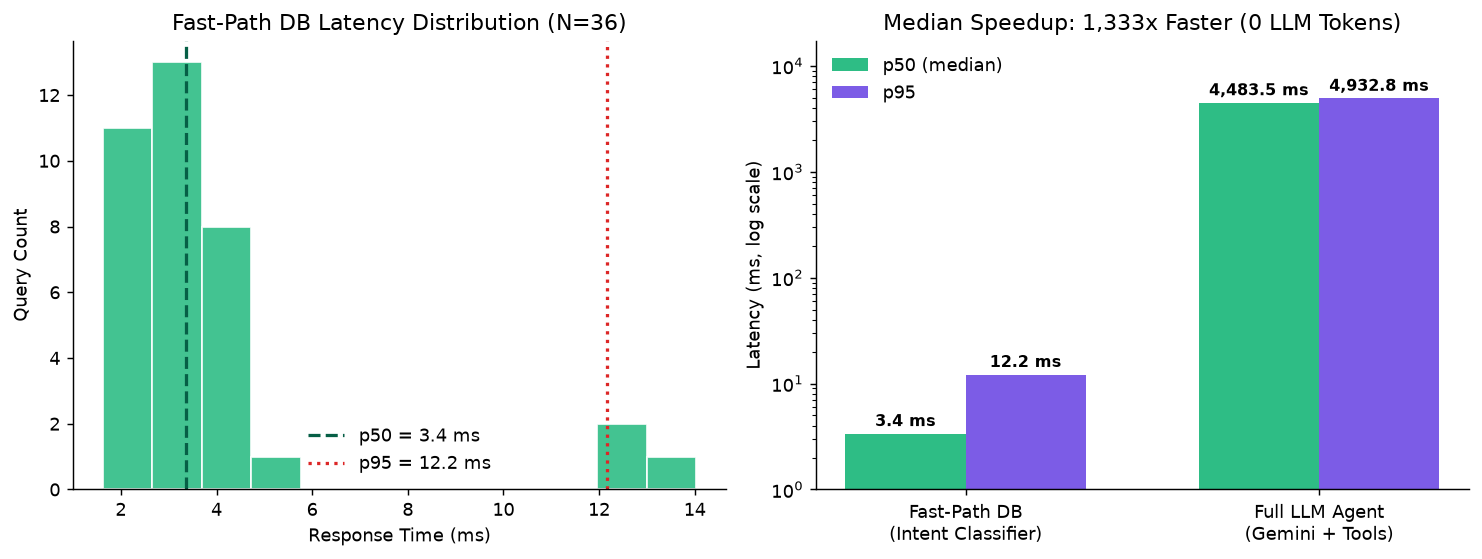

In [4]:
RUN_LIVE_LLM = True

FAST_QUERIES = [
    "150g ức gà bao nhiêu calo?",
    "100g cơm trắng bao nhiêu kcal",
    "thông tin dinh dưỡng 200g cá hồi",
    "trứng gà luộc bao nhiêu đạm",
    "50g yến mạch bao nhiêu calo",
    "nutrition of 150g avocado",
    "calories in 200g broccoli",
    "macros for 100g greek yogurt",
    "giá trị dinh dưỡng hạnh nhân 30g",
    "thịt heo nạc 120g bao nhiêu calo",
    "bánh phở 200g có bao nhiêu carb",
    "tra cứu đậu phộng 50g",
]

# Warm-up 1 DB query so connection pool & SQLAlchemy JIT are warm
async with AsyncSessionLocal() as db:
    await try_fast_food_lookup(db, "100g ức gà bao nhiêu calo")

fast_latencies_ms = []
fast_hits = 0
async with AsyncSessionLocal() as db:
    for _repeat in range(3):
        for q in FAST_QUERIES:
            t0 = time.perf_counter()
            res = await try_fast_food_lookup(db, q)
            dt = (time.perf_counter() - t0) * 1000.0
            if res is not None:
                fast_hits += 1
            fast_latencies_ms.append(dt)

fast_arr = np.array(fast_latencies_ms)
fast_p50 = float(np.percentile(fast_arr, 50))
fast_p95 = float(np.percentile(fast_arr, 95))
fast_mean = float(np.mean(fast_arr))
print(f"Fast-Path DB ({len(fast_latencies_ms)} runs, hit={fast_hits}/{len(fast_latencies_ms)}): "
      f"mean={fast_mean:.2f} ms, p50={fast_p50:.2f} ms, p95={fast_p95:.2f} ms")

llm_latencies_ms = []
llm_sample_queries = FAST_QUERIES[:2]
if RUN_LIVE_LLM and settings.GOOGLE_API_KEY and settings.GOOGLE_API_KEY != "your-gemini-api-key-here":
    async with AsyncSessionLocal() as db:
        for q in llm_sample_queries:
            ctx = AgentToolContext(lookup_food=lambda query: search_foods(db, query))
            t0 = time.perf_counter()
            try:
                _ = await fitness_agent.chat(history=[], user_message=q, tool_context=ctx)
                dt = (time.perf_counter() - t0) * 1000.0
                llm_latencies_ms.append(dt)
            except Exception as exc:
                print(f"LLM skipped for {q!r}: {type(exc).__name__}")

if llm_latencies_ms:
    llm_arr = np.array(llm_latencies_ms)
    llm_p50 = float(np.percentile(llm_arr, 50))
    llm_p95 = float(np.percentile(llm_arr, 95))
    llm_mean = float(np.mean(llm_arr))
    speedup = llm_p50 / fast_p50
    print(f"Live LLM Agent ({len(llm_latencies_ms)} runs): "
          f"mean={llm_mean:.0f} ms, p50={llm_p50:.0f} ms, p95={llm_p95:.0f} ms -> {speedup:.0f}x faster!")
else:
    print("Live LLM benchmark skipped or unavailable.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))

# Panel 1: Fast-Path distribution
ax1.hist(fast_arr, bins=12, color="#2ebd85", edgecolor="white", alpha=0.9)
ax1.axvline(fast_p50, color="#065f46", linestyle="--", linewidth=1.8, label=f"p50 = {fast_p50:.1f} ms")
ax1.axvline(fast_p95, color="#dc2626", linestyle=":", linewidth=1.8, label=f"p95 = {fast_p95:.1f} ms")
ax1.set_xlabel("Response Time (ms)")
ax1.set_ylabel("Query Count")
ax1.set_title(f"Fast-Path DB Latency Distribution (N={len(fast_arr)})")
ax1.legend(frameon=False)

# Panel 2: Fast-Path vs Live LLM comparison
if llm_latencies_ms:
    cats = ["Fast-Path DB\n(Intent Classifier)", "Full LLM Agent\n(Gemini + Tools)"]
    p50_vals = [fast_p50, llm_p50]
    p95_vals = [fast_p95, llm_p95]
    x = np.arange(len(cats))
    w = 0.34
    b1 = ax2.bar(x - w/2, p50_vals, w, label="p50 (median)", color="#2ebd85")
    b2 = ax2.bar(x + w/2, p95_vals, w, label="p95", color="#7c5ce6")
    ax2.set_yscale("log")
    ax2.set_ylim(1, max(p95_vals) * 3.5)
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2, h * 1.18, f"{h:,.1f} ms", ha="center", fontweight="bold", fontsize=9)
    ax2.set_xticks(x, cats)
    ax2.set_ylabel("Latency (ms, log scale)")
    ax2.set_title(f"Median Speedup: {llm_p50 / fast_p50:,.0f}x Faster (0 LLM Tokens)")
    ax2.legend(frameon=False)
else:
    ax2.text(0.5, 0.5, "Set GOOGLE_API_KEY & RUN_LIVE_LLM=True\nto plot live Gemini comparison", ha="center", va="center")
    ax2.set_axis_off()

plt.tight_layout()
plt.savefig(OUT_CHARTS / "03_latency_fastpath_vs_llm.png", bbox_inches="tight")
plt.show()


## 4. API Call Savings & Eval Benchmark Suite Overview
Shows FitAI's 38-question benchmark distribution (`data/eval/eval_questions.csv`) and Gemini API calls saved under realistic food-lookup traffic shares.


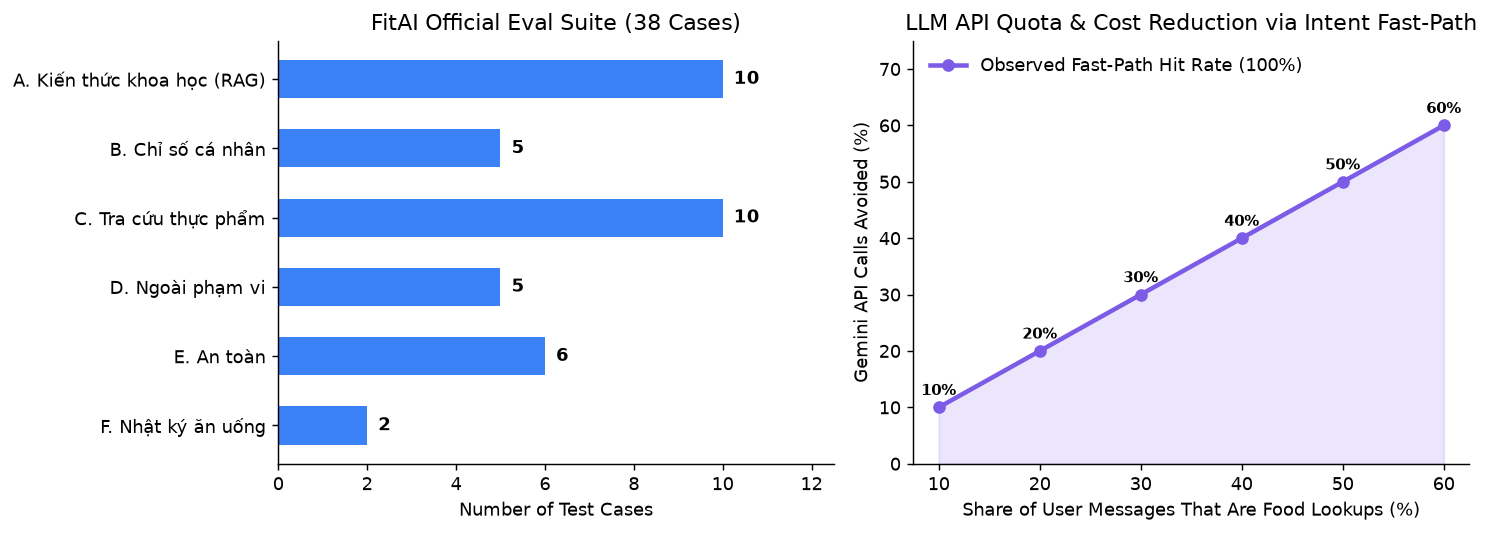

In [5]:
eval_csv = REPO_ROOT / "data" / "eval" / "eval_questions.csv"
group_counts = Counter()
with open(eval_csv, encoding="utf-8") as fh:
    for row in csv.DictReader(fh):
        group_counts[row["nhom"]] += 1

fast_hit_rate = fast_hits / len(fast_latencies_ms) if fast_latencies_ms else 1.0
shares = np.array([10, 20, 30, 40, 50, 60])
calls_saved_pct = shares * fast_hit_rate

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

groups = list(group_counts.keys())
g_vals = [group_counts[g] for g in groups]
bars = ax1.barh(groups[::-1], g_vals[::-1], color="#3b82f6", height=0.55)
for b, v in zip(bars, g_vals[::-1]):
    ax1.text(v + 0.25, b.get_y() + b.get_height()/2, str(v), va="center", fontweight="bold")
ax1.set_xlim(0, max(g_vals) * 1.25)
ax1.set_xlabel("Number of Test Cases")
ax1.set_title(f"FitAI Official Eval Suite ({sum(g_vals)} Cases)")

ax2.plot(shares, calls_saved_pct, marker="o", linewidth=2.5, color="#7c5ce6", label=f"Observed Fast-Path Hit Rate ({fast_hit_rate*100:.0f}%)")
ax2.fill_between(shares, calls_saved_pct, alpha=0.15, color="#7c5ce6")
for sx, sy in zip(shares, calls_saved_pct):
    ax2.text(sx, sy + 2.2, f"{sy:.0f}%", ha="center", fontsize=8.5, fontweight="bold")
ax2.set_xlabel("Share of User Messages That Are Food Lookups (%)")
ax2.set_ylabel("Gemini API Calls Avoided (%)")
ax2.set_ylim(0, 75)
ax2.set_title("LLM API Quota & Cost Reduction via Intent Fast-Path")
ax2.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig(OUT_CHARTS / "04_eval_suite_and_quota_savings.png", bbox_inches="tight")
plt.show()
